# Experiment: fixed samples, three seeds, validation fusion diagnosis
Use all four HCRL CSV files. No previous checkpoints or feature cache required. This new experiment preserves prior outputs.

**Stage A (default Run all):** 5,000 training windows total, 2,000 validation total; fixed samples; four ablations × three training seeds × 30 epochs. Data preparation happens once for development. Save resumable checkpoints each epoch. Select best checkpoint using validation macro AP, preserving the original fixed 25% residual fusion rule for full-model checkpoint selection.

**Stage B (disabled by default):** 4,000 test windows total from later rows, after settings are frozen. Enable only when development is complete. Runtime depends on GPU and Drive; no 30-minute guarantee.

Upload DoS_dataset.csv, Fuzzy_dataset.csv, gear_dataset.csv, RPM_dataset.csv to `/content`, or change DATA_DIR. Mount Drive and run all. Keep the same output folder/settings to resume. The notebook trains fresh models for the new validation protocol; it does not resume the earlier exp3 weights.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path
from types import SimpleNamespace
import csv,json,hashlib,time,random,os,copy
import numpy as np
import pandas as pd
import torch
from torch import nn
import torch.nn.functional as F
from sklearn.metrics import average_precision_score,roc_auc_score,accuracy_score,balanced_accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,roc_curve,precision_recall_curve
import matplotlib.pyplot as plt
DATA_DIR=Path('/content')
FILES={'DoS':'DoS_dataset.csv','Fuzzy':'Fuzzy_dataset.csv','Gear':'gear_dataset.csv','RPM':'RPM_dataset.csv'}
OUT=Path('/content/drive/MyDrive/CAN_ATCNet/HCRL_FixedSamples_3Seeds_v1')
C=SimpleNamespace(window=32,hidden=64,id_embedding=16,dilations=[1,2,4,8],dropout=.1,id_dropout=.05,focal_gamma=2.,consistency_weight=.2,residual_bce_weight=1.)
SAMPLE_SEED=42
TRAIN_SEEDS=[42,123,2026]
SEED=SAMPLE_SEED
BASE_OUT=OUT
FUSION_GRID=[0.,.1,.25,.5]
TEST_BOUNDS=(400064,600064)
TEST_WINDOWS=4000
EPOCHS=30
BATCH_SIZE=256
VARIANTS=['tcn_ce','tcn_focal','tcn_predictive','can_atcnet']
LIMITS={'train':5000,'val':2000}
BOUNDS={'train':(0,200000),'val':(200032,400032)}
MAX_ROWS=400032
NF=49
CLASSES=['Normal','DoS','Fuzzy','Gear','RPM']
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(2)
if DEVICE.type=='cuda':torch.backends.cuda.matmul.allow_tf32=True
print('Device:',torch.cuda.get_device_name(0) if DEVICE.type=='cuda' else 'CPU')
def seed_all(seed):
    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
    if torch.cuda.is_available():torch.cuda.manual_seed_all(seed)
def save_json(path,obj):
    p=Path(path);tmp=p.with_suffix(p.suffix+'.tmp');tmp.write_text(json.dumps(obj,indent=2,allow_nan=False));os.replace(tmp,p)
def read_prefix(path):
    if not path.is_file():raise FileNotFoundError(f'Upload DoS_dataset.csv to Colab Files or set DATA to its actual path: {path}')
    records=[];digest=hashlib.sha256()
    with path.open('rb') as f:
        for i in range(MAX_ROWS):
            line=f.readline()
            if not line:raise ValueError(f'Need {MAX_ROWS} rows; file ended at {i}.')
            digest.update(line);r=next(csv.reader([line.decode('utf-8-sig').strip()]))
            try:
                t=float(r[0]);cid=int(r[1],16);d=int(r[2]);flag=r[-1].strip().upper()
                if not np.isfinite(t) or not 0<=cid<2**29 or not 0<=d<=8 or flag not in {'T','R'}:raise ValueError('Invalid fields')
                body=r[3:-1]
                if len(body)<d or any(v.strip() for v in body[8:]):raise ValueError('Payload length')
                b=[int(v.strip(),16) for v in body[:d]]
                if any(v<0 or v>255 for v in b):raise ValueError('Payload byte')
                records.append((t,cid,d,b+[0]*(8-d),int(flag=='T')))
            except Exception as e:raise ValueError(f'Invalid data row {i+1}: {e}') from e
    return records,digest.hexdigest()
def features(records):
    n=len(records);x=np.zeros((n,NF),np.float32);ids=np.zeros(n,np.uint32);labels=np.zeros(n,np.int64);last=None;byid={}
    for j,(t,cid,d,b,y) in enumerate(records):
        dt=0. if last is None else t-last
        if dt<0:raise ValueError(f'Decreasing timestamp at block row {j}; no silent sorting or clamping.')
        seen=cid in byid;di=t-byid[cid] if seen else 0.
        x[j,:8]=np.asarray(b,np.float32)/255.;x[j,8:16]=np.arange(8)<d;x[j,16]=d/8.
        x[j,17:20]=[np.log1p(dt*1e6),np.log1p(di*1e6),float(seen)]
        x[j,20:]=[(cid>>k)&1 for k in range(28,-1,-1)]
        ids[j]=cid;labels[j]=y;last=t;byid[cid]=t
    return x,ids,labels
def prepare():
    global ID_VALUES,CLASS_WEIGHTS
    tick=time.monotonic();missing=[str(DATA_DIR/f) for f in FILES.values() if not (DATA_DIR/f).is_file()]
    if missing:raise FileNotFoundError('Upload all four CSVs or change DATA_DIR. Missing: '+', '.join(missing))
    raw={};hashes={}
    for attack,filename in FILES.items():
        records,digest=read_prefix(DATA_DIR/filename);hashes[attack]=digest
        if any(records[i][0]<records[i-1][0] for i in range(1,len(records))):raise ValueError(f'{filename}: decreasing timestamps; inspect source, no silent repair.')
        class_id=CLASSES.index(attack)
        for split,(a,b) in BOUNDS.items():
            x,ids,y=features(records[a:b]);raw[(attack,split)]=(x,ids,y*class_id)
        print('Parsed fixed prefix:',filename,flush=True)
    tx=np.concatenate([raw[(a,'train')][0][:,17:19] for a in FILES]);mean=tx.mean(0,dtype=np.float64);std=tx.std(0,dtype=np.float64).clip(1e-3)
    ID_VALUES=np.unique(np.concatenate([raw[(a,'train')][1] for a in FILES]));pools={};audit=[];indices=[]
    for si,split in enumerate(LIMITS):
        arrays={k:[] for k in ['x','token','y','clean']}
        for ai,attack in enumerate(FILES):
            x,ids,y=raw[(attack,split)];x[:,17:19]=(x[:,17:19]-mean)/std
            loc=np.searchsorted(ID_VALUES,ids);ok=(loc<len(ID_VALUES))&(ID_VALUES[np.minimum(loc,len(ID_VALUES)-1)]==ids);tokens=np.where(ok,loc+1,0)
            starts=np.arange(0,len(x)-C.window+1,C.window);n=LIMITS[split]//len(FILES)
            if len(starts)<n:raise ValueError('Insufficient disjoint windows')
            starts=np.sort(np.random.default_rng(SAMPLE_SEED+si*100+ai).choice(starts,n,replace=False));ix=starts[:,None]+np.arange(C.window)
            labels=y[ix[:,-1]];clean=(y[ix].sum(1)==0)
            arrays['x'].append(x[ix]);arrays['token'].append(tokens[ix]);arrays['y'].append(labels);arrays['clean'].append(clean)
            audit.append(dict(file=FILES[attack],split=split,windows=n,normal=int((labels==0).sum()),attack=int((labels>0).sum()),clean_windows=int(clean.sum())))
            indices.extend(dict(file=FILES[attack],split=split,start_row=int(s+BOUNDS[split][0]+1),end_row=int(s+BOUNDS[split][0]+C.window)) for s in starts)
        pools[split]={k:torch.as_tensor(np.concatenate(v),device=DEVICE) for k,v in arrays.items()};pools[split]['token']=pools[split]['token'].long()
        if set(pools[split]['y'].cpu().tolist())!=set(range(len(CLASSES))):raise ValueError(f'{split}: one or more classes absent in fixed sample. Do not silently resample; review the sampling protocol.')
    counts=torch.bincount(pools['train']['y'],minlength=len(CLASSES)).float();CLASS_WEIGHTS=counts.sum()/(len(CLASSES)*counts)
    protocol=dict(version='fixed-sample-three-seed-1',prefix_hashes=hashes,rows_per_file=MAX_ROWS,bounds=BOUNDS,limits=LIMITS,seed=SAMPLE_SEED,training_seeds=TRAIN_SEEDS,fusion_grid=FUSION_GRID,test_bounds=TEST_BOUNDS,test_windows=TEST_WINDOWS,epochs=EPOCHS,batch_size=BATCH_SIZE,variants=VARIANTS,model=vars(C),classes=CLASSES,learning_rate=.001,weight_decay=.0001,sampling='equal allocation per file; uniform disjoint windows within fixed chronological blocks',label='last frame',fusion=[.75,.25])
    protocol=json.loads(json.dumps(protocol));run_hash=hashlib.sha256(json.dumps(protocol,sort_keys=True).encode()).hexdigest();OUT.mkdir(parents=True,exist_ok=True)
    if (OUT/'protocol.json').exists() and json.loads((OUT/'protocol.json').read_text())!=protocol:raise ValueError('Changed protocol: use a new OUT folder.')
    save_json(OUT/'protocol.json',protocol);save_json(OUT/'preprocessor.json',dict(mean=mean.tolist(),std=std.tolist(),ids=ID_VALUES.tolist(),classes=CLASSES))
    pd.DataFrame(audit).to_csv(OUT/'sample_audit.csv',index=False);pd.DataFrame(indices).to_csv(OUT/'sample_indices.csv',index=False)
    print(pd.DataFrame(audit).to_string(index=False));print('Preparation seconds:',round(time.monotonic()-tick,2))
    return pools,run_hash


Device: Tesla T4


## Predeclared protocol
Train rows 1–200,000; validation rows 200,033–400,032; held-out rows 400,065–600,064 of each CSV. The held-out block is beyond the rows in the experiments shared so far; verify you have not used it elsewhere. Previously viewed pilot test rows are now explicitly development data, not an untouched test.

Uniform disjoint 32-frame windows, equal allocation per file, no label-based resampling. Sampling seed is fixed at 42 independently of training seeds 42, 123, 2026. Label is the last frame. Normal prediction requires all frames normal. Normalization and ID vocabulary use training blocks only. All ablations share samples. No future-frame access, timestamp repair or silent row removal.

Full-model diagnostics compare classifier-only, residual-only binary scores, and residual weights 0, .1, .25, .5 on validation. Choose one weight by mean validation macro AP across the three seeds; ties favor the smallest weight. A zero weight is a legitimate result, not suppressed. This search uses the same validation set as checkpoint selection and can overfit it; held-out evaluation is needed. Do not select a seed based on test performance.

Chronological blocks from the same recordings are not independent capture/vehicle validation. Three-seed standard deviations measure training variability; they are not population confidence intervals. No external validation or novelty claim is established here.


In [ ]:
class CausalConv(nn.Module):
    def __init__(self,c,k,d):
        super().__init__();self.pad=(k-1)*d;self.conv=nn.Conv1d(c,c,k,dilation=d)
    def forward(self,x):return self.conv(F.pad(x,(self.pad,0)))
class CausalBlock(nn.Module):
    def __init__(self,c,d):
        super().__init__();self.c1=CausalConv(c,3,d);self.c2=CausalConv(c,3,d);self.n1=nn.LayerNorm(c);self.n2=nn.LayerNorm(c);self.drop=nn.Dropout(C.dropout)
    def forward(self,x):
        h=self.drop(F.gelu(self.n1(self.c1(x).transpose(1,2)))).transpose(1,2)
        h=self.drop(F.gelu(self.n2(self.c2(h).transpose(1,2)))).transpose(1,2)
        return x+h
class CANATCNet(nn.Module):
    def __init__(self):
        super().__init__();self.ids=nn.Embedding(len(ID_VALUES)+1,C.id_embedding)
        self.input=nn.Linear(NF+C.id_embedding,C.hidden)
        self.blocks=nn.Sequential(*[CausalBlock(C.hidden,d) for d in C.dilations])
        self.classifier=nn.Linear(C.hidden,len(CLASSES))
        self.predictor=nn.Sequential(nn.Linear(C.hidden+C.id_embedding+1,C.hidden),nn.GELU(),nn.Linear(C.hidden,10))
        self.consistency=nn.Sequential(nn.Linear(11,32),nn.GELU(),nn.Linear(32,1))
    def encode(self,x,tokens):
        z=self.ids(tokens);h=self.input(torch.cat([x,z],-1));return self.blocks(h.transpose(1,2)).transpose(1,2)
    def forward(self,x,tokens):
        if self.training and C.id_dropout:
            tokens=tokens.masked_fill(torch.rand(tokens.shape,device=tokens.device)<C.id_dropout,0)
        h=self.encode(x,tokens);last=x[:,-1]
        # h[t-1] contains no current payload/timing. Current ID/DLC are observed at arrival.
        expected=self.predictor(torch.cat([h[:,-2],self.ids(tokens[:,-1]),last[:,16:17]],-1))
        predicted=torch.cat([expected[:,:8].sigmoid(),expected[:,8:]],-1)
        observed=torch.cat([last[:,:8],last[:,17:19]],-1)
        mask=torch.cat([last[:,8:16],torch.ones_like(last[:,19:20]),last[:,19:20]],-1)
        element=F.smooth_l1_loss(predicted,observed,reduction='none')*mask
        residual=element.sum(-1)/mask.sum(-1).clamp_min(1)
        # Detach prevents attack BCE from teaching the normal predictor to manufacture errors.
        features=torch.cat([torch.log1p(element.detach()),last[:,19:20]],-1)
        return self.classifier(h[:,-1]),self.consistency(features).squeeze(-1),residual

def forward_variant(model,x,tokens,variant):
    if variant in {'tcn_ce','tcn_focal'}:
        if model.training and C.id_dropout:
            tokens=tokens.masked_fill(torch.rand(tokens.shape,device=tokens.device)<C.id_dropout,0)
        return model.classifier(model.encode(x,tokens)[:,-1]),None,None
    return model(x,tokens)
def objective(model,batch,variant):
    logits,consistency,residual=forward_variant(model,batch['x'],batch['token'],variant)
    logits=logits.float();y=batch['y']
    if variant=='tcn_ce':return F.cross_entropy(logits,y)
    logp=F.log_softmax(logits,-1).gather(1,y[:,None]).squeeze(1)
    classification=-(CLASS_WEIGHTS[y]*(1-logp.exp()).pow(C.focal_gamma)*logp).mean()
    if variant=='tcn_focal':return classification
    normal=batch['clean'].float()
    prediction=(residual.float()*normal).sum()/normal.sum().clamp_min(1)
    if variant=='tcn_predictive':return classification+C.consistency_weight*prediction
    binary=(y!=0).float();sample_weight=CLASS_WEIGHTS[y]
    consistency_loss=(F.binary_cross_entropy_with_logits(consistency.float(),binary,reduction='none')*sample_weight).mean()
    return classification+C.consistency_weight*prediction+C.consistency_weight*C.residual_bce_weight*consistency_loss


In [ ]:
@torch.inference_mode()
def predict(model,pool,variant):
    model.eval();out=[]
    for start in range(0,len(pool['y']),BATCH_SIZE):
        logits,c,_=forward_variant(model,pool['x'][start:start+BATCH_SIZE],pool['token'][start:start+BATCH_SIZE],variant)
        p=logits.float().softmax(-1)
        if variant=='can_atcnet':
            attack=p[:,1:].sum(-1,keepdim=True);fused=.75*attack+.25*c.float().sigmoid()[:,None]
            p=torch.cat([1-fused,fused*p[:,1:]/attack.clamp_min(1e-12)],-1)
        out.append(p.cpu().numpy())
    return np.concatenate(out)
def atomic_checkpoint(path,state):
    tmp=path.with_suffix('.tmp');torch.save(state,tmp);os.replace(tmp,path)
def train(variant,pools,run_hash):
    seed_all(SEED);model=CANATCNet().to(DEVICE);opt=torch.optim.AdamW(model.parameters(),lr=.001,weight_decay=.0001)
    path=OUT/f'{variant}_last.pt';history=[];best_ap=-1.;best=None;start_epoch=1
    if path.exists():
        state=torch.load(path,map_location=DEVICE,weights_only=True)
        if state['run_hash']!=run_hash:raise ValueError('Checkpoint protocol mismatch')
        model.load_state_dict(state['model']);opt.load_state_dict(state['optimizer']);history=state['history'];best_ap=state['best_ap'];best=state['best_model'];start_epoch=state['epoch']+1
        print(variant,'resuming after epoch',state['epoch'])
    pool=pools['train'];val_y=pools['val']['y'].cpu().numpy()
    for epoch in range(start_epoch,EPOCHS+1):
        seed_all(SEED+epoch);tick=time.monotonic();model.train();order=torch.randperm(len(pool['y']),device=DEVICE);loss_sum=0.
        for start in range(0,len(order),BATCH_SIZE):
            ix=order[start:start+BATCH_SIZE];batch={k:v[ix] for k,v in pool.items()};opt.zero_grad(set_to_none=True)
            loss=objective(model,batch,variant)
            if not torch.isfinite(loss):raise ValueError('Nonfinite loss')
            loss.backward();torch.nn.utils.clip_grad_norm_(model.parameters(),5.);opt.step();loss_sum+=loss.item()*len(ix)
        scores=predict(model,pools['val'],variant);ap=float(average_precision_score(np.eye(len(CLASSES))[val_y],scores,average="macro"))
        if ap>best_ap:best_ap=ap;best={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
        entry=dict(model=variant,epoch=epoch,loss=loss_sum/len(order),val_AP=ap,seconds_before_save=time.monotonic()-tick);history.append(entry)
        atomic_checkpoint(path,dict(run_hash=run_hash,epoch=epoch,model=model.state_dict(),optimizer=opt.state_dict(),best_model=best,best_ap=best_ap,history=history))
        pd.DataFrame(history).to_csv(OUT/f'{variant}_history.csv',index=False)
        print(entry,'checkpoint saved',flush=True)
    model.load_state_dict(best)
    return model,history


In [ ]:
@torch.inference_mode()
def components(model,pool):
    model.eval();ps=[];rs=[]
    for start in range(0,len(pool['y']),BATCH_SIZE):
        logits,r,_=model(pool['x'][start:start+BATCH_SIZE],pool['token'][start:start+BATCH_SIZE]);ps.append(logits.float().softmax(-1).cpu().numpy());rs.append(r.float().sigmoid().cpu().numpy())
    return np.concatenate(ps),np.concatenate(rs)
def fuse(p,r,alpha):
    a=p[:,1:].sum(1,keepdims=True);q=(1-alpha)*a+alpha*r[:,None]
    return np.concatenate([1-q,q*p[:,1:]/np.maximum(a,1e-12)],axis=1)
def measure(y,p):
    pred=p.argmax(1)
    return dict(accuracy=float(accuracy_score(y,pred)),balanced_accuracy=float(balanced_accuracy_score(y,pred)),macro_F1=float(f1_score(y,pred,labels=range(5),average='macro',zero_division=0)),macro_AP=float(average_precision_score(np.eye(5)[y],p,average='macro')),macro_AUC=float(roc_auc_score(y,p,multi_class='ovr',average='macro')))
def run_development():
    global OUT,SEED
    OUT=BASE_OUT;SEED=SAMPLE_SEED;pools,run_hash=prepare();all_rows=[];fusion_rows=[]
    y=pools['val']['y'].cpu().numpy()
    for seed in TRAIN_SEEDS:
        SEED=seed;OUT=BASE_OUT/f'seed_{seed}';OUT.mkdir(parents=True,exist_ok=True)
        for variant in VARIANTS:
            model,history=train(variant,pools,run_hash);p=predict(model,pools['val'],variant)
            all_rows.append(dict(seed=seed,model=variant,**measure(y,p)))
            np.savez_compressed(OUT/f'{variant}_validation.npz',labels=y,probabilities=p)
            if variant=='can_atcnet':
                cp,r=components(model,pools['val']);np.savez_compressed(OUT/'full_components_validation.npz',labels=y,classifier=cp,residual=r)
                for alpha in FUSION_GRID:fusion_rows.append(dict(seed=seed,alpha=alpha,**measure(y,fuse(cp,r,alpha))))
                save_json(OUT/'residual_validation.json',dict(binary_AP=float(average_precision_score(y>0,r)),binary_AUC=float(roc_auc_score(y>0,r))))
            pd.DataFrame(all_rows).to_csv(BASE_OUT/'validation_by_seed.csv',index=False)
            del model
    OUT=BASE_OUT;table=pd.DataFrame(all_rows);fusion=pd.DataFrame(fusion_rows)
    table.groupby('model')[['accuracy','balanced_accuracy','macro_F1','macro_AP','macro_AUC']].agg(['mean','std']).to_csv(OUT/'validation_summary.csv')
    fusion.to_csv(OUT/'fusion_validation_by_seed.csv',index=False)
    selection=fusion.groupby('alpha').macro_AP.mean().sort_index();best_alpha=float(selection.idxmax())
    frozen=dict(run_hash=run_hash,training_seeds=TRAIN_SEEDS,alpha=best_alpha,selection_metric='mean validation macro AP across all predeclared seeds; ties use smallest alpha',test_bounds=TEST_BOUNDS,test_windows=TEST_WINDOWS,sample_seed=SAMPLE_SEED)
    frozen=json.loads(json.dumps(frozen))
    frozen_path=OUT/'frozen_selection.json'
    if frozen_path.exists() and json.loads(frozen_path.read_text())!=frozen:raise ValueError('Frozen settings differ. Use a new experiment directory.')
    save_json(frozen_path,frozen)
    # Paired differences describe seed variability, not independent population confidence intervals.
    wide=table.pivot(index='seed',columns='model',values='macro_AP')
    (wide.subtract(wide['tcn_focal'],axis=0)).to_csv(OUT/'paired_validation_AP_vs_focal.csv')
    print(table.to_string(index=False));print('Validation-selected residual fusion weight:',best_alpha)
    print('Development complete. Held-out test has not been loaded or scored.')
    return table

def prepare_test():
    global MAX_ROWS
    pre=json.loads((BASE_OUT/'preprocessor.json').read_text());mean=np.asarray(pre['mean']);std=np.asarray(pre['std']);vocab=np.asarray(pre['ids']);arrays={k:[] for k in ['x','token','y','clean']};indices=[];hashes={};audit=[]
    old=MAX_ROWS
    try:
        MAX_ROWS=TEST_BOUNDS[1]
        for ai,(attack,filename) in enumerate(FILES.items()):
            records,digest=read_prefix(DATA_DIR/filename);hashes[filename]=digest
            if any(records[i][0]<records[i-1][0] for i in range(1,len(records))):raise ValueError('Nonmonotonic source timestamps')
            x,ids,y=features(records[TEST_BOUNDS[0]:TEST_BOUNDS[1]]);y*=CLASSES.index(attack);x[:,17:19]=(x[:,17:19]-mean)/std
            loc=np.searchsorted(vocab,ids);ok=(loc<len(vocab))&(vocab[np.minimum(loc,len(vocab)-1)]==ids);tokens=np.where(ok,loc+1,0)
            starts=np.arange(0,len(x)-C.window+1,C.window);n=TEST_WINDOWS//4
            starts=np.sort(np.random.default_rng(SAMPLE_SEED+900+ai).choice(starts,n,replace=False));ix=starts[:,None]+np.arange(C.window)
            labels=y[ix[:,-1]]
            for k,v in dict(x=x[ix],token=tokens[ix],y=labels,clean=(y[ix].sum(1)==0)).items():arrays[k].append(v)
            indices.extend(dict(file=filename,start_row=int(s+TEST_BOUNDS[0]+1),end_row=int(s+TEST_BOUNDS[0]+C.window)) for s in starts)
            audit.append(dict(file=filename,normal=int((labels==0).sum()),attack=int((labels>0).sum())))
    finally:MAX_ROWS=old
    pool={k:torch.as_tensor(np.concatenate(v),device=DEVICE) for k,v in arrays.items()};pool['token']=pool['token'].long()
    if set(pool['y'].cpu().tolist())!=set(range(5)):raise ValueError('Held-out sample misses classes; do not silently resample.')
    pd.DataFrame(indices).to_csv(BASE_OUT/'heldout_indices.csv',index=False);pd.DataFrame(audit).to_csv(BASE_OUT/'heldout_class_audit.csv',index=False);save_json(BASE_OUT/'heldout_prefix_hashes.json',hashes)
    return pool

def run_heldout():
    global ID_VALUES
    frozen=json.loads((BASE_OUT/'frozen_selection.json').read_text());protocol=json.loads((BASE_OUT/'protocol.json').read_text())
    expected=hashlib.sha256(json.dumps(protocol,sort_keys=True).encode()).hexdigest()
    if frozen['run_hash']!=expected:raise ValueError('Frozen protocol mismatch')
    # Confirm development bytes/config unchanged before touching held-out rows.
    global OUT,SEED
    OUT=BASE_OUT;SEED=SAMPLE_SEED
    _,current_hash=prepare()
    if current_hash!=expected:raise ValueError('Development data/settings changed')
    if frozen['test_bounds']!=list(TEST_BOUNDS) or frozen['test_windows']!=TEST_WINDOWS:raise ValueError('Held-out settings changed')
    ID_VALUES=np.asarray(json.loads((BASE_OUT/'preprocessor.json').read_text())['ids']);pool=prepare_test();y=pool['y'].cpu().numpy();rows=[]
    for seed in TRAIN_SEEDS:
        folder=BASE_OUT/f'seed_{seed}'
        for variant in VARIANTS:
            state=torch.load(folder/f'{variant}_last.pt',map_location=DEVICE,weights_only=True)
            if state['run_hash']!=expected or state['epoch']!=EPOCHS:raise ValueError('Checkpoint incomplete or incompatible')
            model=CANATCNet().to(DEVICE);model.load_state_dict(state['best_model']);outputs={variant:predict(model,pool,variant)}
            if variant=='can_atcnet':
                cp,r=components(model,pool)
                np.savez_compressed(folder/'full_components_heldout.npz',labels=y,classifier=cp,residual=r)
                outputs['full_classifier_only']=cp
                outputs['full_validation_selected_fusion']=fuse(cp,r,frozen['alpha'])
            for name,p in outputs.items():
                rows.append(dict(seed=seed,model=name,**measure(y,p)));np.savez_compressed(folder/f'{name}_heldout.npz',labels=y,probabilities=p)
                cm=confusion_matrix(y,p.argmax(1),labels=range(5));pd.DataFrame(cm,index=CLASSES,columns=CLASSES).to_csv(folder/f'{name}_heldout_confusion.csv')
                details=[]
                for k,cl in enumerate(CLASSES):
                    truth=y==k;guess=p.argmax(1)==k;details.append(dict(class_name=cl,support=int(truth.sum()),precision=float(precision_score(truth,guess,zero_division=0)),recall=float(recall_score(truth,guess)),F1=float(f1_score(truth,guess,zero_division=0))))
                pd.DataFrame(details).to_csv(folder/f'{name}_heldout_per_class.csv',index=False)
            pd.DataFrame(rows).to_csv(BASE_OUT/'heldout_by_seed.csv',index=False);del model
    table=pd.DataFrame(rows);summary=table.groupby('model')[['accuracy','balanced_accuracy','macro_F1','macro_AP','macro_AUC']].agg(['mean','std']);summary.to_csv(BASE_OUT/'heldout_summary.csv')
    print(summary.to_string());print('All seeds reported. Do not select the winning seed or retune on these results.')
    fig,ax=plt.subplots(figsize=(10,4));m=table.groupby('model').macro_F1.agg(['mean','std']);ax.bar(m.index,m['mean'],yerr=m['std'].fillna(0));ax.tick_params(axis='x',rotation=30);ax.set(ylabel='Macro F1 (mean ± seed SD)',ylim=(0,1));fig.tight_layout();fig.savefig(BASE_OUT/'heldout_macro_F1.png',dpi=180);plt.show()
    return table


In [ ]:
DEVELOPMENT_RESULTS=run_development()

Parsed fixed prefix: DoS_dataset.csv
Parsed fixed prefix: Fuzzy_dataset.csv
Parsed fixed prefix: gear_dataset.csv
Parsed fixed prefix: RPM_dataset.csv
             file split  windows  normal  attack  clean_windows
  DoS_dataset.csv train     1250     952     298            692
Fuzzy_dataset.csv train     1250    1084     166            746
 gear_dataset.csv train     1250    1017     233            520
  RPM_dataset.csv train     1250    1020     230            524
  DoS_dataset.csv   val      500     410      90            326
Fuzzy_dataset.csv   val      500     408      92            253
 gear_dataset.csv   val      500     424      76            254
  RPM_dataset.csv   val      500     418      82            221
Preparation seconds: 65.11
{'model': 'tcn_ce', 'epoch': 1, 'loss': 0.6266420427799225, 'val_AP': 0.8285284019279329, 'seconds_before_save': 3.360074898999983} checkpoint saved
{'model': 'tcn_ce', 'epoch': 2, 'loss': 0.2065788004398346, 'val_AP': 0.9396961776123283, 'second

## Held-out evaluation
After development is complete and you accept the frozen settings, change the switch below to True and run this cell. It reports every ablation and seed, the original fixed fusion, classifier-only full-model output, and the validation-selected fusion. No model/seed selection is performed on test results. Once seen, do not retune against this block.


Parsed fixed prefix: DoS_dataset.csv
Parsed fixed prefix: Fuzzy_dataset.csv
Parsed fixed prefix: gear_dataset.csv
Parsed fixed prefix: RPM_dataset.csv
             file split  windows  normal  attack  clean_windows
  DoS_dataset.csv train     1250     952     298            692
Fuzzy_dataset.csv train     1250    1084     166            746
 gear_dataset.csv train     1250    1017     233            520
  RPM_dataset.csv train     1250    1020     230            524
  DoS_dataset.csv   val      500     410      90            326
Fuzzy_dataset.csv   val      500     408      92            253
 gear_dataset.csv   val      500     424      76            254
  RPM_dataset.csv   val      500     418      82            221
Preparation seconds: 54.99
                                 accuracy           balanced_accuracy            macro_F1            macro_AP           macro_AUC          
                                     mean       std              mean       std      mean       std      m

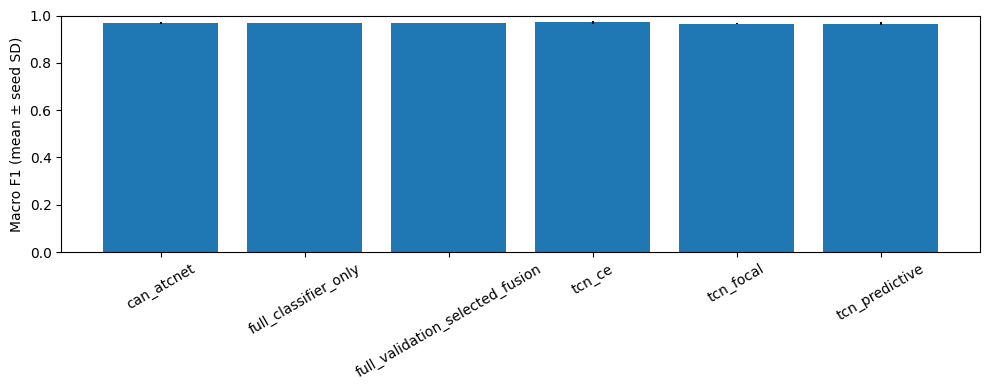

In [ ]:
RUN_HELDOUT=True
if RUN_HELDOUT:
    HELDOUT_RESULTS=run_heldout()
else:
    print('Held-out evaluation disabled. Review development results first.')

In [ ]:
# Diagnostic analysis: explain metric trade-offs without retuning on held-out data.
from math import comb

def multiclass_calibration(y,p,bins=15):
    p=np.asarray(p,float)
    p=np.clip(p,1e-12,1-1e-12)
    conf=p.max(1); pred=p.argmax(1); correct=(pred==y).astype(float)
    nll=float(-np.log(p[np.arange(len(y)),y]).mean())
    one=np.eye(p.shape[1])[y]
    brier=float(np.mean(np.sum((p-one)**2,axis=1)))
    ece=0.0
    edges=np.linspace(0,1,bins+1)
    for lo,hi in zip(edges[:-1],edges[1:]):
        m=(conf>=lo)&(conf<(hi if hi<1 else hi+1e-12))
        if m.any():
            ece+=float(m.mean()*abs(correct[m].mean()-conf[m].mean()))
    return nll,brier,ece

def mcnemar_exact(b,c):
    n=int(b+c)
    if n==0:return 1.0
    k=min(int(b),int(c))
    tail=sum(comb(n,i) for i in range(k+1))/(2**n)
    return float(min(1.0,2*tail))

def run_diagnostics():
    class_rows=[];cal_rows=[];overlap_rows=[];res_rows=[];res_class_rows=[]
    for seed in TRAIN_SEEDS:
        folder=BASE_OUT/f'seed_{seed}'
        probs={}
        for path in folder.glob('*_heldout.npz'):
            if path.name=='full_components_heldout.npz':
                continue
            z=np.load(path); y=z['labels']; probs[path.stem.replace('_heldout','')]=z['probabilities']
        if 'tcn_ce' not in probs or 'can_atcnet' not in probs:
            raise ValueError(f'Missing diagnostic probability files for seed {seed}')
        for model,p in sorted(probs.items()):
            pred=p.argmax(1)
            nll,brier,ece=multiclass_calibration(y,p)
            cal_rows.append(dict(seed=seed,model=model,NLL=nll,Brier=brier,ECE_15=ece))
            for k,cl in enumerate(CLASSES):
                truth=(y==k); guess=(pred==k)
                class_rows.append(dict(
                    seed=seed,model=model,class_name=cl,support=int(truth.sum()),
                    precision=float(precision_score(truth,guess,zero_division=0)),
                    recall=float(recall_score(truth,guess,zero_division=0)),
                    F1=float(f1_score(truth,guess,zero_division=0)),
                    AP=float(average_precision_score(truth.astype(int),p[:,k]))
                ))
        a=probs['tcn_ce'].argmax(1)==y
        b=probs['can_atcnet'].argmax(1)==y
        tcn_only=int((a&~b).sum()); can_only=int((~a&b).sum())
        overlap_rows.append(dict(
            seed=seed,both_correct=int((a&b).sum()),both_wrong=int((~a&~b).sum()),
            tcn_ce_only_correct=tcn_only,can_atcnet_only_correct=can_only,
            mcnemar_exact_p=mcnemar_exact(tcn_only,can_only)
        ))
        z=np.load(folder/'full_components_heldout.npz')
        ry=z['labels']; r=z['residual']; cp=z['classifier']; cp_pred=cp.argmax(1)
        res_rows.append(dict(
            seed=seed,binary_AP=float(average_precision_score(ry>0,r)),
            binary_AUC=float(roc_auc_score(ry>0,r)),
            residual_mean_correct=float(r[cp_pred==ry].mean()),
            residual_mean_wrong=float(r[cp_pred!=ry].mean()),
            classifier_attack_prob_residual_corr=float(np.corrcoef(cp[:,1:].sum(1),r)[0,1])
        ))
        for k,cl in enumerate(CLASSES):
            m=ry==k
            res_class_rows.append(dict(seed=seed,class_name=cl,support=int(m.sum()),residual_mean=float(r[m].mean()),residual_std=float(r[m].std())))

    pd.DataFrame(class_rows).to_csv(BASE_OUT/'diagnostic_per_class.csv',index=False)
    pd.DataFrame(cal_rows).to_csv(BASE_OUT/'diagnostic_calibration.csv',index=False)
    pd.DataFrame(overlap_rows).to_csv(BASE_OUT/'diagnostic_error_overlap.csv',index=False)
    pd.DataFrame(res_rows).to_csv(BASE_OUT/'diagnostic_residual.csv',index=False)
    pd.DataFrame(res_class_rows).to_csv(BASE_OUT/'diagnostic_residual_by_class.csv',index=False)

    print('DIAGNOSTIC_PER_CLASS')
    print(pd.DataFrame(class_rows).to_string(index=False))
    print('DIAGNOSTIC_CALIBRATION')
    print(pd.DataFrame(cal_rows).to_string(index=False))
    print('DIAGNOSTIC_ERROR_OVERLAP')
    print(pd.DataFrame(overlap_rows).to_string(index=False))
    print('DIAGNOSTIC_RESIDUAL')
    print(pd.DataFrame(res_rows).to_string(index=False))
    print('DIAGNOSTIC_RESIDUAL_BY_CLASS')
    print(pd.DataFrame(res_class_rows).to_string(index=False))
    return {
        'per_class':pd.DataFrame(class_rows),
        'calibration':pd.DataFrame(cal_rows),
        'overlap':pd.DataFrame(overlap_rows),
        'residual':pd.DataFrame(res_rows),
        'residual_by_class':pd.DataFrame(res_class_rows)
    }

DIAGNOSTICS=run_diagnostics()


In [ ]:
# Exploratory selective-fusion confirmation experiment
# IMPORTANT: the earlier held-out block has already been inspected. To avoid tuning against it,
# this follow-up trains the combiner on validation only and evaluates on a new later confirmation block.

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

CONFIRM_BOUNDS=(600096,800096)
CONFIRM_WINDOWS=4000

def combiner_features(p,residual):
    p=np.asarray(p,float)
    r=np.asarray(residual,float).reshape(-1,1)
    conf=p.max(1,keepdims=True)
    s=np.sort(p,axis=1)
    margin=(s[:,-1]-s[:,-2]).reshape(-1,1)
    entropy=(-np.sum(np.clip(p,1e-12,1)*np.log(np.clip(p,1e-12,1)),axis=1)).reshape(-1,1)
    attack=p[:,1:].sum(1,keepdims=True)
    return np.concatenate([p,r,conf,margin,entropy,attack],axis=1)

def prepare_confirmation():
    pre=json.loads((BASE_OUT/'preprocessor.json').read_text())
    mean=np.asarray(pre['mean']); std=np.asarray(pre['std']); vocab=np.asarray(pre['ids'])
    arrays={k:[] for k in ['x','token','y','clean']}
    audit=[]; hashes={}
    old=globals()['MAX_ROWS']
    try:
        globals()['MAX_ROWS']=CONFIRM_BOUNDS[1]
        for ai,(attack,filename) in enumerate(FILES.items()):
            records,digest=read_prefix(DATA_DIR/filename); hashes[filename]=digest
            x,ids,y=features(records[CONFIRM_BOUNDS[0]:CONFIRM_BOUNDS[1]])
            y*=CLASSES.index(attack)
            x[:,17:19]=(x[:,17:19]-mean)/std
            loc=np.searchsorted(vocab,ids)
            ok=(loc<len(vocab))&(vocab[np.minimum(loc,len(vocab)-1)]==ids)
            tokens=np.where(ok,loc+1,0)
            starts=np.arange(0,len(x)-C.window+1,C.window)
            n=CONFIRM_WINDOWS//4
            starts=np.sort(np.random.default_rng(SAMPLE_SEED+1900+ai).choice(starts,n,replace=False))
            ix=starts[:,None]+np.arange(C.window)
            labels=y[ix[:,-1]]
            arrays['x'].append(x[ix]); arrays['token'].append(tokens[ix]); arrays['y'].append(labels); arrays['clean'].append((y[ix].sum(1)==0))
            audit.append(dict(file=filename,normal=int((labels==0).sum()),attack=int((labels>0).sum())))
    finally:
        globals()['MAX_ROWS']=old
    pool={k:torch.as_tensor(np.concatenate(v),device=DEVICE) for k,v in arrays.items()}
    pool['token']=pool['token'].long()
    if set(pool['y'].cpu().tolist())!=set(range(5)):
        raise ValueError('Confirmation block misses classes; do not silently resample.')
    pd.DataFrame(audit).to_csv(BASE_OUT/'confirmation_class_audit.csv',index=False)
    save_json(BASE_OUT/'confirmation_protocol.json',dict(
        bounds=CONFIRM_BOUNDS,windows=CONFIRM_WINDOWS,
        training='multinomial logistic combiner fitted on validation features only',
        features=['tcn_ce_probs','can_atcnet_residual','tcn_confidence','tcn_margin','tcn_entropy','tcn_attack_prob'],
        note='post-hoc exploratory follow-up using a later untouched confirmation block'
    ))
    return pool

def run_selective_combiner_confirmation():
    global ID_VALUES
    ID_VALUES=np.asarray(json.loads((BASE_OUT/'preprocessor.json').read_text())['ids'])
    pool=prepare_confirmation(); y_conf=pool['y'].cpu().numpy()
    rows=[]; overlap=[]
    for seed in TRAIN_SEEDS:
        folder=BASE_OUT/f'seed_{seed}'
        # Validation-only combiner training
        z=np.load(folder/'tcn_ce_validation.npz')
        y_val=z['labels']; p_val=z['probabilities']
        comp=np.load(folder/'full_components_validation.npz')
        r_val=comp['residual']
        X_val=combiner_features(p_val,r_val)
        comb=make_pipeline(
            StandardScaler(),
            LogisticRegression(max_iter=2000,C=1.0,solver='lbfgs',random_state=seed)
        )
        comb.fit(X_val,y_val)

        # Load frozen best checkpoints and score the new confirmation block
        st_tcn=torch.load(folder/'tcn_ce_last.pt',map_location=DEVICE,weights_only=True)
        st_full=torch.load(folder/'can_atcnet_last.pt',map_location=DEVICE,weights_only=True)
        mt=CANATCNet().to(DEVICE); mt.load_state_dict(st_tcn['best_model'])
        mf=CANATCNet().to(DEVICE); mf.load_state_dict(st_full['best_model'])
        p_tcn=predict(mt,pool,'tcn_ce')
        _,r_conf=components(mf,pool)
        X_conf=combiner_features(p_tcn,r_conf)
        p_comb=comb.predict_proba(X_conf)

        rows.append(dict(seed=seed,model='tcn_ce',**measure(y_conf,p_tcn)))
        rows.append(dict(seed=seed,model='selective_combiner',**measure(y_conf,p_comb)))

        a=p_tcn.argmax(1)==y_conf; b=p_comb.argmax(1)==y_conf
        tcn_only=int((a&~b).sum()); comb_only=int((~a&b).sum())
        overlap.append(dict(seed=seed,both_correct=int((a&b).sum()),both_wrong=int((~a&~b).sum()),
                            tcn_only_correct=tcn_only,combiner_only_correct=comb_only,
                            mcnemar_exact_p=mcnemar_exact(tcn_only,comb_only)))

        np.savez_compressed(folder/'selective_combiner_confirmation.npz',
                            labels=y_conf,tcn_ce=p_tcn,combiner=p_comb,residual=r_conf)
        del mt,mf

    table=pd.DataFrame(rows)
    table.to_csv(BASE_OUT/'confirmation_by_seed.csv',index=False)
    table.groupby('model')[['accuracy','balanced_accuracy','macro_F1','macro_AP','macro_AUC']].agg(['mean','std']).to_csv(BASE_OUT/'confirmation_summary.csv')
    pd.DataFrame(overlap).to_csv(BASE_OUT/'confirmation_error_overlap.csv',index=False)

    print('CONFIRMATION_BY_SEED')
    print(table.to_string(index=False))
    print('CONFIRMATION_SUMMARY')
    print(table.groupby('model')[['accuracy','balanced_accuracy','macro_F1','macro_AP','macro_AUC']].agg(['mean','std']).to_string())
    print('CONFIRMATION_ERROR_OVERLAP')
    print(pd.DataFrame(overlap).to_string(index=False))
    return table

CONFIRMATION_RESULTS=run_selective_combiner_confirmation()
